# Bike Sharing Predictive Analysis
**By Anshuman · Next-day hourly demand forecasting**

One row is one system-wide hour; the regression target is `cnt`, observed rental trips.
At **11:59 PM on the previous calendar day**, forecast all **24 hourly counts for the next day**
(a lead time of about 1 minute to 23 hours 1 minute to hourly slot starts).
A hypothetical operations manager currently uses last week's same-hour rentals to plan aggregate
service capacity and staffing; we compare that rule with machine learning. These data cannot allocate
bikes to individual stations, and observed trips do not measure unmet demand.

Primary metric: **MAE in rentals/hour**; secondary: RMSE. No random time-series splitting.
This is a historical rolling-origin evaluation, not a claim of deployment.

## 1. Real data and audit
The public UCI `hour.csv` is the source, never a synthetic fallback. The single Python entry point verifies its SHA-256 checksum. Only hourly observations are used; future daily aggregates are excluded. The full hourly grid exposes missing records; **missing target values stay NaN**.
The audit covers the whole file to define coverage and split dates. EDA used to understand modeling
patterns is restricted to the proper fitting period, before calibration and testing.

In [1]:
from pathlib import Path
import os, sys
# Limit nested numeric parallelism for reproducible, modest CPU use.
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/bike-mpl')
ROOT = Path.cwd()
if not (ROOT / 'bike_sharing.py').exists() and (ROOT.parent / 'bike_sharing.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'bike_sharing.py').exists():
    raise RuntimeError('Run this notebook from the repository root; see README for Colab checkout steps.')
sys.path.insert(0, str(ROOT))
import json, numpy as np, pandas as pd
from IPython.display import display, Markdown, Image
from bike_sharing import (prepare, fit_first, run_advanced, save_results,
                             score, FEATURES, NUMERIC, CATEGORICAL, issue_times)
from bike_sharing import eda, evaluation_plots, explain_cases, business_plot
pd.set_option('display.max_columns', 20)
(ROOT / 'reports').mkdir(exist_ok=True)
d = prepare()
print(json.dumps(d['audit'], indent=2))

{
  "source_rows": 17379,
  "source_columns": 17,
  "source_start": "2011-01-01 00:00:00",
  "source_end": "2012-12-31 23:00:00",
  "full_grid_hours": 17544,
  "missing_hours": 165,
  "sha256_hour_csv": "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f",
  "fit_start": "2011-01-08 23:00:00",
  "fit_end": "2012-10-07 23:00:00",
  "fit_rows": 15195,
  "calibration_start": "2012-10-08 00:00:00",
  "calibration_end": "2012-11-04 23:00:00",
  "calibration_rows": 636,
  "test_start": "2012-11-05 00:00:00",
  "test_end": "2012-12-30 23:00:00",
  "test_rows": 1302,
  "test_scheduled_hours": 1344,
  "test_missing_actuals": 4,
  "test_missing_week_lag_with_actual": 38,
  "terminal_hours_not_tested": 24
}


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
timestamp,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,dtype
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


,Full-source target distribution
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


Duplicate timestamps: 0
Original missing cells: 0


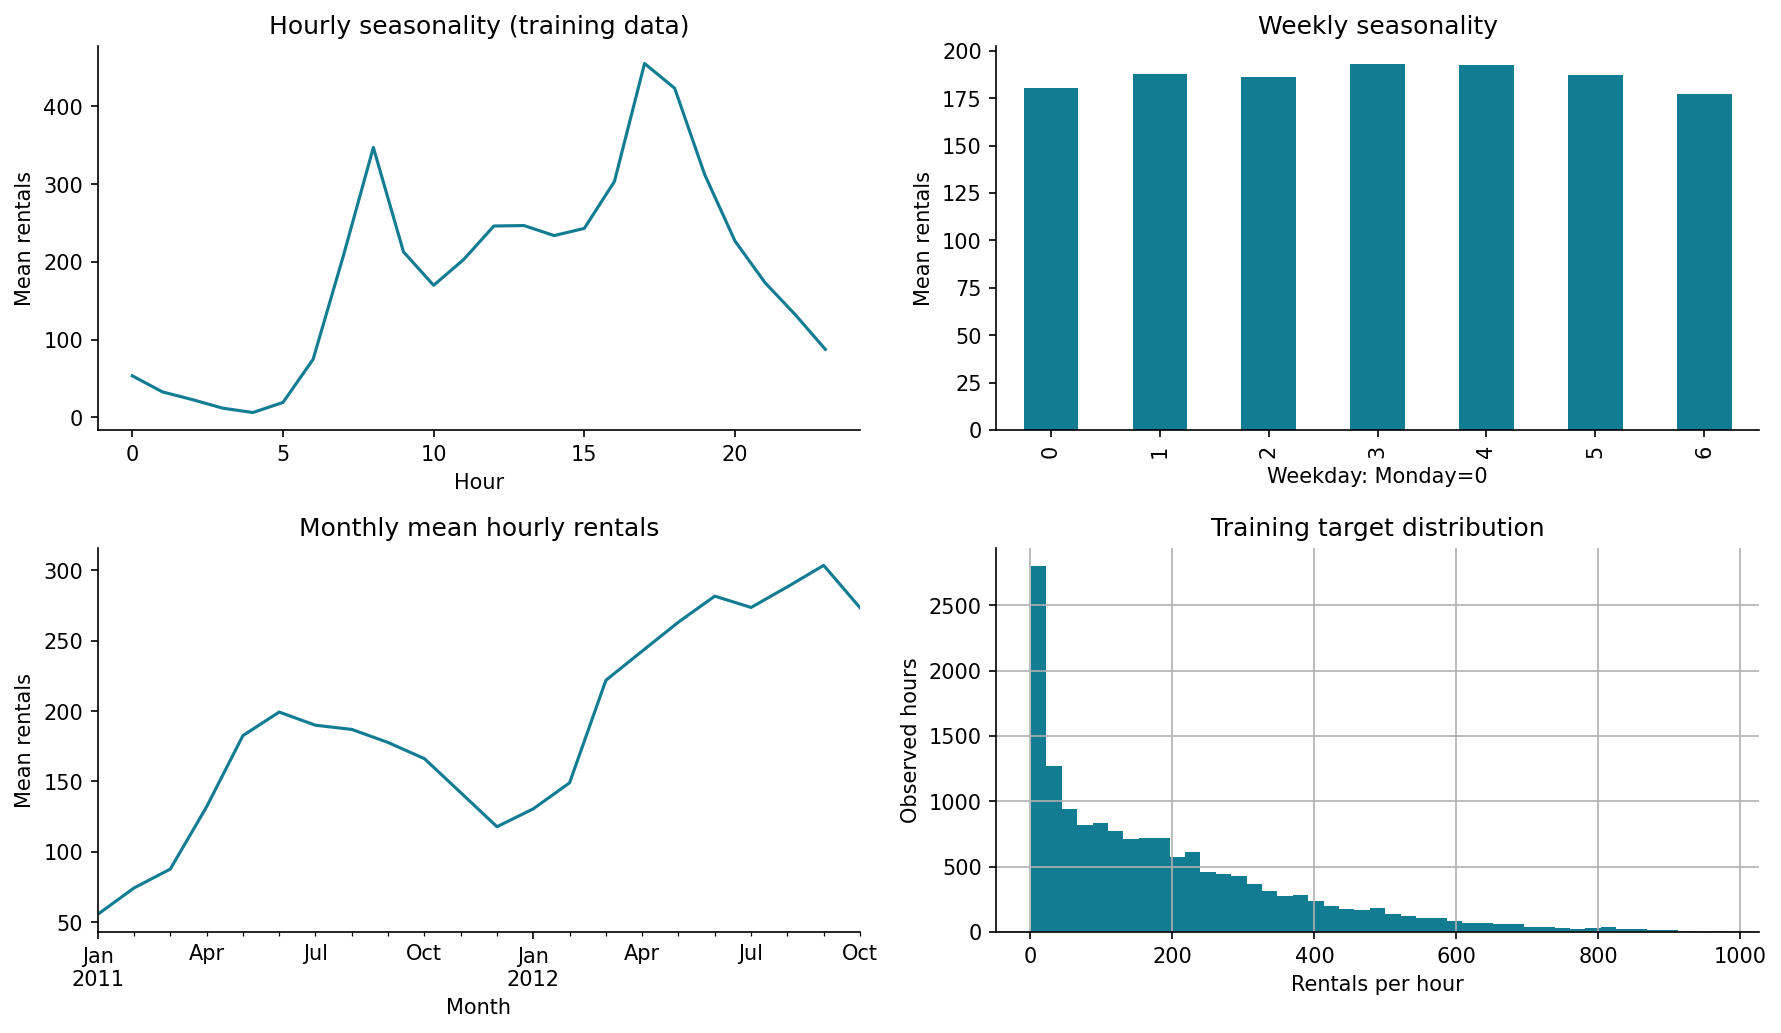

In [2]:
display(d['raw'].head())
display(d['raw'].dtypes.rename('dtype').to_frame())
display(d['raw']['cnt'].describe().to_frame('Full-source target distribution'))
print('Duplicate timestamps:', d['raw'].index.duplicated().sum())
print('Original missing cells:', int(d['raw'].isna().sum().sum()))
display(Image(filename=str(eda(d))))

## 2. Leakage audit and forecast-time availability
| Raw columns | Treatment and reason |
|---|---|
| `cnt` | Target only. Never a contemporaneous feature. |
| `casual`, `registered` | Excluded: components whose sum is `cnt`. |
| `temp`, `atemp`, `hum`, `windspeed`, `weathersit` | Excluded: observed at the future target hour; no historical forecast archive exists here. No future-aware interpolation. |
| `instant` | Excluded: arbitrary row identifier. |
| `dteday` | Index construction only, not a raw predictor. |
| `hr`, `weekday`, `mnth`, `yr` | Replaced by explicitly derived hour, weekday, month, and elapsed calendar time. |
| `season` | Excluded: month captures known annual calendar information. Error slices use explicit meteorological seasons. |
| `holiday`, `workingday` | Calendar information assumed published before issuance; holiday is mapped by date, workingday recomputed from weekday and holiday. No target-dependent filling. |

`lag_24`, `lag_48`, `lag_168` reference the **exact timestamp**, including missing hours.
For a target at time t, seven-day mean, maximum, and observed count use the 168 slots
**[t − 191 hours, t − 24 hours]**. Means/maxima ignore missing historical observations; the count exposes
how much history was observed. Missing lag features are median-imputed inside each training pipeline.
No target is imputed for fitting or scoring.

All historical sources end no later than the previous day's same hour, hence before the common
11:59 PM issuance. Assuming that an hour's count is finalized by 11:59 PM that day is an explicit
operational assumption; a reporting delay would require an additional lag.
The calendar itself is known in advance. Tests perturb all target-day and later counts/weather and
check that all 24 forecast rows remain unchanged.

Original extensions beyond Session 11 include **lag_48**, **seven-day rolling maximum**,
**workday × commute-hour interaction**, and observed-history count. Cyclic hour features and a calendar
trend are also included. These choices were fixed before viewing test metrics; no feature was kept or
removed based on test performance.

In [3]:
display(d['X'].loc[d['fit'][:5]])
print('Features:', FEATURES)
for lag in (24,48,168):
    assert ((d['X'].index-pd.Timedelta(hours=lag)) < issue_times(d['X'].index)).all()
assert ((d['X'].index-pd.Timedelta(hours=24)) < issue_times(d['X'].index)).all()
print('All lag and rolling-window end timestamps precede daily issuance.')

,hour,dow,month,holiday,workingday,lag_24,lag_48,lag_168,roll_mean_7d,roll_max_7d,roll_count_7d,commute_workday,hour_sin,hour_cos,trend_days
timestamp,,,,,,,,,,,,,,,
2011-01-08 23:00:00,23,5,1,0.0,0,15.0,23.0,39.0,58.465839,219.0,161.0,0,-0.258819,0.965926,7.958333
2011-01-09 00:00:00,0,6,1,0.0,0,25.0,17.0,17.0,58.521739,219.0,161.0,0,0.000000,1.000000,8.000000
2011-01-09 01:00:00,1,6,1,0.0,0,16.0,7.0,17.0,58.372671,219.0,161.0,0,0.258819,0.965926,8.041667
2011-01-09 02:00:00,2,6,1,0.0,0,16.0,1.0,9.0,58.273292,219.0,161.0,0,0.500000,0.866025,8.083333
2011-01-09 03:00:00,3,6,1,0.0,0,7.0,NaN,6.0,58.236025,219.0,161.0,0,0.707107,0.707107,8.125000


Features: ['hour', 'dow', 'month', 'holiday', 'workingday', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_7d', 'roll_max_7d', 'roll_count_7d', 'commute_workday', 'hour_sin', 'hour_cos', 'trend_days']
All lag and rolling-window end timestamps precede daily issuance.


## 3. Chronological splitting and evaluation contract
The last **eight complete Monday–Sunday calendar weeks** are the held-out test window.
December 31 is a partial terminal week and is not used for model selection or testing.
Four preceding weeks are reserved exclusively for conformal calibration, including in Milestone 2 so
that the first model stays comparable in later notebooks. All earlier observed rows after the fixed
191-hour history warm-up train both models. Dates and row counts are printed below.

All methods are scored on **identical observed target hours with an observed 168-hour lag**.
Missing baseline references cause exclusion from the common metric sample; they are never fabricated.
This can bias evaluation toward hours with good history and is a stated limitation. Models can still
forecast all 24 hours using train-only imputation; only scoring requires observed targets and baseline.

The fitted model is frozen through calibration and testing. For each next day, past test-day observations
may refresh lag features after they have actually occurred. This is rolling-origin **daily feature
updating**, not a single 56-day forecast and not test-target fitting. No current-day count is used in
any of that day's 24 forecasts.

In [4]:
display(pd.Series(d['audit']).to_frame('Value'))
print('No overlap:', d['fit'].max() < d['cal'].min() < d['test'].min())
print('Scheduled test hours:', d['audit']['test_scheduled_hours'])
print('Missing actuals excluded:', d['audit']['test_missing_actuals'])
print('Missing baseline with observed target excluded:', d['audit']['test_missing_week_lag_with_actual'])

,Value
source_rows,17379
source_columns,17
source_start,2011-01-01 00:00:00
source_end,2012-12-31 23:00:00
full_grid_hours,17544
missing_hours,165
sha256_hour_csv,e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60f...
fit_start,2011-01-08 23:00:00
fit_end,2012-10-07 23:00:00
fit_rows,15195


No overlap: True
Scheduled test hours: 1344
Missing actuals excluded: 4
Missing baseline with observed target excluded: 38


## 4. Seasonal baseline and first regression
The baseline is the observed count exactly 168 hours earlier. Ridge regression (`alpha=10`, fixed in
advance) uses a `ColumnTransformer` plus `Pipeline`: median imputation and scaling for numeric features,
one-hot calendar encoding with unknown-category handling, then regression. Every fitted transformation
sees proper training only. Negative predictions are clipped to zero as a prespecified physical constraint.

In [5]:
ridge_model, ridge_pred = fit_first(d)
first_predictions = pd.DataFrame({'actual': d['y'].loc[d['test']],
    'seasonal_naive': d['X'].loc[d['test'], 'lag_168'], 'ridge': ridge_pred})
first_metrics = pd.DataFrame({name: score(first_predictions.actual, first_predictions[name])
                              for name in ['seasonal_naive','ridge']}).T
gain = first_metrics.loc['seasonal_naive','MAE']-first_metrics.loc['ridge','MAE']
display(first_metrics)
print(f'Ridge absolute MAE improvement: {gain:.3f} rentals/hour; percentage: {100*gain/first_metrics.iloc[0].MAE:.2f}%')
print(ridge_model)
# A genuine daily API issues 24 forecasts from strictly prior-day history.
from bike_sharing import forecast_day
first_day = d['test'][0].normalize()
daily_forecast = forecast_day(ridge_model, d['grid'], first_day, holiday=int(d['grid'].loc[first_day, 'holiday']))
assert len(daily_forecast) == 24
display(daily_forecast)
first_metrics.to_csv(ROOT/'results/milestone2_metrics.csv')

,MAE,RMSE
seasonal_naive,71.948541,119.503996
ridge,64.104873,96.101284


Ridge absolute MAE improvement: 7.844 rentals/hour; percentage: 10.90%
Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['lag_24', 'lag_48',
                                                   'lag_168', 'roll_mean_7d',
                                                   'roll_max_7d',
                                                   'roll_count_7d',
                                                   'commute_w

,forecast,seasonal_naive
timestamp,,
2012-11-05 00:00:00,68.916776,22.0
2012-11-05 01:00:00,98.711579,NaN
2012-11-05 02:00:00,65.109459,NaN
2012-11-05 03:00:00,54.853179,NaN
2012-11-05 04:00:00,52.105438,NaN
2012-11-05 05:00:00,58.106890,NaN
2012-11-05 06:00:00,77.775890,NaN
2012-11-05 07:00:00,154.949002,NaN
2012-11-05 08:00:00,217.705708,NaN


## 5. Held-out week and residuals
The plotted week is the first test week, specified in advance. All lines use the common scoring rows.

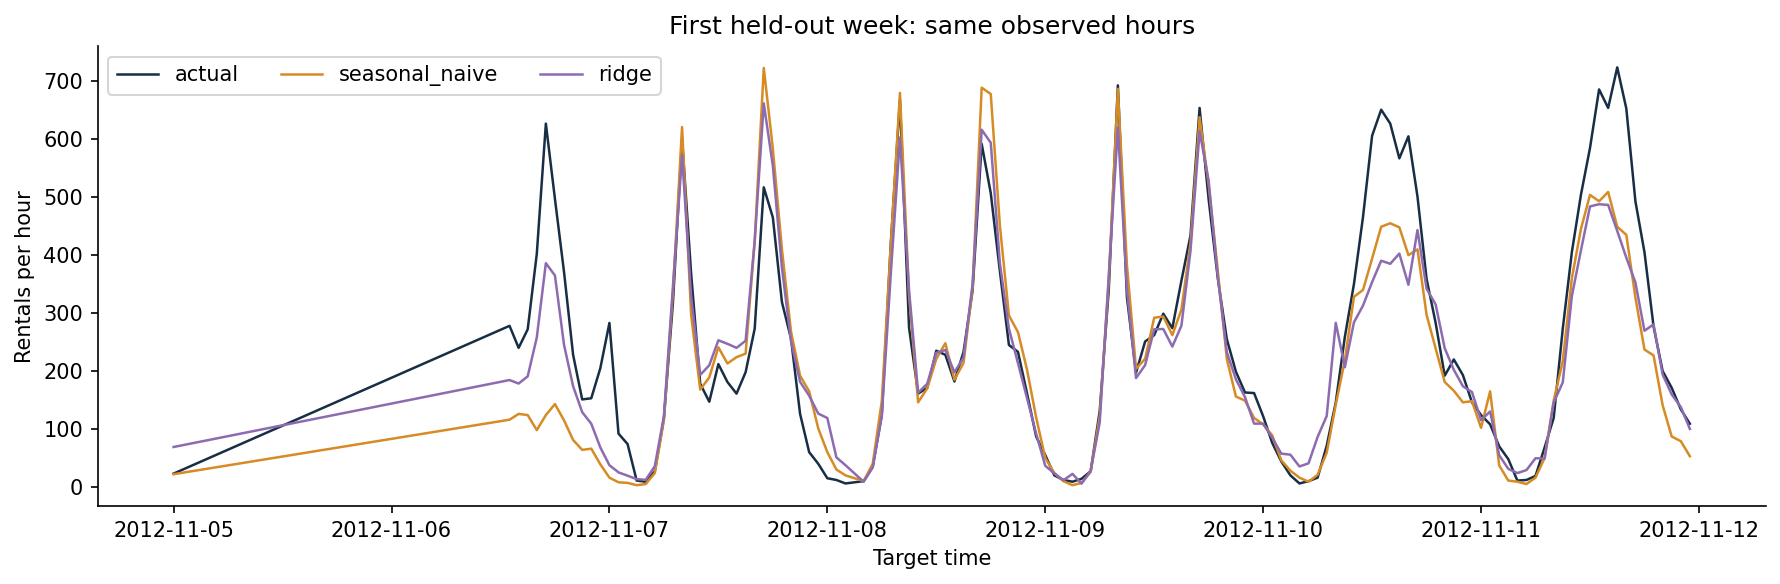

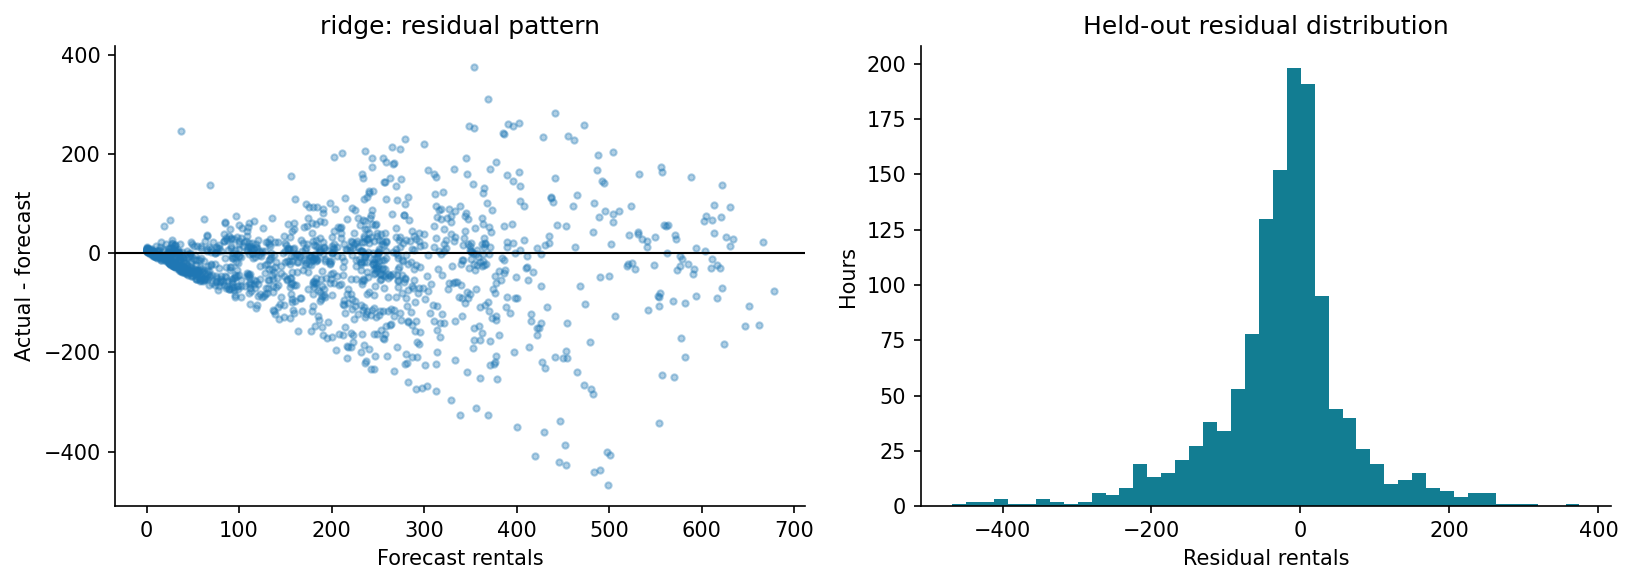

In [6]:
evaluation_plots(first_predictions)
display(Image(filename=str(ROOT/'visualizations/milestone2_week.png')))
display(Image(filename=str(ROOT/'visualizations/milestone2_residuals.png')))

## Academic honesty and reproducibility
OpenAI Codex assisted with code, documentation, tests, charts, and drafting the memo/slides. All reported
results come from executed code on the uploaded real data. The author is responsible for reviewing and understanding the
splits, leakage audit, baseline, SHAP, interval assumptions, and cost proxy.
The repository is published on GitHub; no course submission is claimed. The forecasting approach was informed by ISOM 835 course concepts: chronological validation,
training-only preprocessing, seasonal baselines, SHAP and uncertainty. The implementation uses
project-specific availability checks and feature engineering. Source data are credited to UCI and
Fanaee-T & Gama (2013). See `coursework/README.md` for the requirement mapping and attribution.
No instructor notebooks, lecture pages or templates are distributed with this project.

Missing targets are preserved; no synthetic fallback or future observed weather is used.
SHAP describes the fitted model, not causal effects. No station-level or realized-savings claim is made.